In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import glob

# ----------------------------------------------------------------------
# 1. Configuration & Parameters
# ----------------------------------------------------------------------
BASE_DIR = Path("output_poiseuille")

# SPECIFY YOUR PARAMETERS HERE
TARGET_H0 = 0.000000
TARGET_OMEGA = 0.000000

# Physical parameters from phaseField_poiseuille.cpp
Fx = 1e-4              # Body force applied in simulation

# Lattice / fluid properties
cs2 = 1.0 / 3.0        # Speed of sound squared
rho_l = 1.0
rho_h = 1.975
eta_l = 0.0025
eta_h = 0.05

# ----------------------------------------------------------------------
# 2. Corrected Kinematic Viscosity (matches update_Sf in simulation)
# ----------------------------------------------------------------------
def effective_nu(phi, rho_l, rho_h, eta_l, eta_h, cs2):
    """
    Compute the kinematic viscosity actually used by the MRT scheme.
    This mimics the logic of update_Sf() for a given phase field phi.
    """
    term_l = rho_l * cs2 / eta_l      # dt = 1
    term_h = rho_h * cs2 / eta_h
    term   = term_l + phi * (term_h - term_l)
    s_v    = term / (1.0 + 0.5 * term)    # Sf[7] = Sf[1] = Sf[2] = Sf[8] in the code
    nu     = cs2 * (1.0 / s_v - 0.5)
    return nu

# Since phi is initialised to 1.0 everywhere, we use phi = 1.0
nu_sim = effective_nu(1.0, rho_l, rho_h, eta_l, eta_h, cs2)

# ----------------------------------------------------------------------
# 3. Path Construction (matches C++ output folder naming)
# ----------------------------------------------------------------------
def get_path_for_params(h0, omega):
    """Constructs the folder path based on C++ directory naming logic."""
    folder_name = f"output_{h0:.6f}_{omega:.6f}"
    folder_path = BASE_DIR / folder_name
    
    if not folder_path.exists():
        raise FileNotFoundError(f"Directory not found: {folder_path}")
    
    # Try to find the final output file (adjust filename if you use a different output interval)
    files = sorted(glob.glob(str(folder_path / "output_t_100000.csv")))
    if not files:
        raise FileNotFoundError(f"No CSV files found in {folder_path}")
        
    return Path(files[-1])

# ----------------------------------------------------------------------
# 4. Data Loading & Analytical Formula
# ----------------------------------------------------------------------
def load_profile(csv_path):
    # df = pd.read_csv(csv_path)
    df = pd.read_csv(csv_path, skipinitialspace=True)
    nX = df["i"].max() + 1
    nY = df["j"].max() + 1
    
    # Extract vertical slice from the middle of the channel
    mid_x = nX // 2
    slice_data = df[df['i'] == mid_x].sort_values('j')
    
    return nY, slice_data['j'].values, slice_data['ux'].values

def analytical_poiseuille(y, F, rho, nu, H):
    """Formula for mid-grid bounce-back (walls at -0.5 and H-0.5)."""
    return (F / (2.0 * rho * nu)) * (y + 0.5) * (H - 0.5 - y)

# ----------------------------------------------------------------------
# 5. Execution and Visualization
# ----------------------------------------------------------------------
try:
    csv_file = get_path_for_params(TARGET_H0, TARGET_OMEGA)
    H, y_sim, u_sim = load_profile(csv_file)
    
    print(f"Plotting results for H0={TARGET_H0}, Omega={TARGET_OMEGA}")
    print(f"Source: {csv_file}")
    print(f"Theoretical nu (from MRT relaxation): {nu_sim:.4f}")
    print(f"Max Velocity (Sim): {np.max(u_sim):.6f}")

    # Generate analytical curve
    y_fine = np.linspace(0, H - 1, 500)
    rho_sim = rho_l + 1.0 * (rho_h - rho_l) # Since phi=1.0
    u_theory = analytical_poiseuille(y_fine, Fx, rho_sim, nu_sim, H)

    # Plot
    plt.figure(figsize=(8, 6))
    plt.plot(u_theory, y_fine, 'k--', lw=2, label=f'Analytical (nu={nu_sim:.4f})')
    plt.scatter(u_sim, y_sim, color='royalblue', s=25, alpha=0.7, label='LBM Simulation')

    plt.xlabel("Velocity $u_x$", fontsize=12)
    plt.ylabel("Lattice Position $y$", fontsize=12)
    plt.title(f"Velocity Profile: $H_0={TARGET_H0}$, $\omega={TARGET_OMEGA}$", fontsize=14)
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error: {e}")

Error: Directory not found: output_poiseuille/output_0.000000_0.000000


Saved plot to validation_plot.png


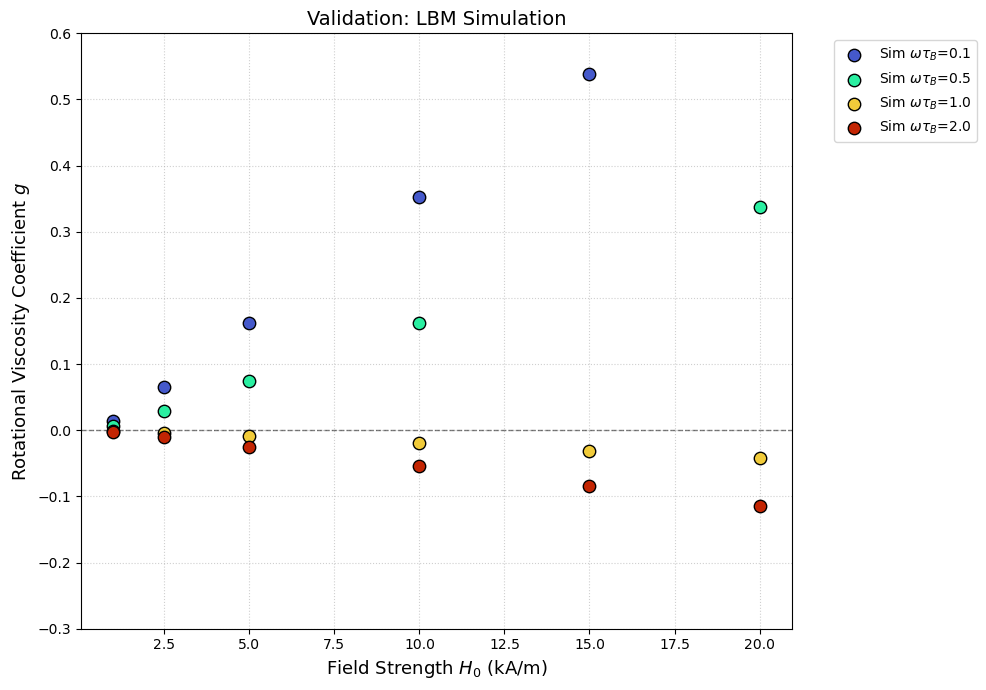

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
from scipy.special import iv

# --- 1. Constants (from phaseField_poiseuille.cpp) ---
nX, nY = 100, 25
phi_val = 1.0
F_px = 1e-4
tauB = 4.0
Href = 126.1585
Ms = 40.0 / Href
chi0 = 2.2

# Fluid properties
rho_l, rho_h = 1.0, 1.975
eta_l, eta_h = 0.0025, 0.05

# Effective base properties since phi = 1.0 everywhere initially
rho_base = rho_l + phi_val * (rho_h - rho_l) # 1.975
eta_base = eta_l + phi_val * (eta_h - eta_l) # 0.05

def poiseuille_theory(y, eta_eff):
    """
    Theoretical Poiseuille flow profile. 
    y bounds are -0.5 and nY-0.5 due to mid-grid bounce back.
    """
    return (F_px / (2.0 * eta_eff)) * (y + 0.5) * (nY - 0.5 - y)

def calculate_g_theory_2D(H0_real, wtB):
    """
    2D rotational viscosity coefficient g, consistent with the phase-field LBM simulation.
    H0_real is the physical field strength (in kA/m).
    """
    H0_real_arr = np.asarray(H0_real, dtype=float)
    H0_lbm = H0_real_arr / Href
    
    # xi = 2.0 * chi0 * H0_lbm / Ms
    xi = H0_real
    
    L_2D = np.where(xi < 1e-8, 0.5*xi, iv(1, xi) / iv(0, xi))
    
    # g_lbm = Delta_eta_lbm / (phi * eta_base)
    g_lbm = (tauB * Ms * L_2D * H0_lbm * (1.0 - wtB**2)) / (4.0 * eta_base * (1.0 + wtB**2)**2)
    
    # The classical Shliomis definition for g includes a 3/2 factor multiplier.
    g_physical = g_lbm * 1.5
    
    return np.nan_to_num(g_physical)

# --- 2. Simulation Data Processing ---
base_path = "output_poiseuille"
results = []

if os.path.exists(base_path):
    for folder in os.listdir(base_path):
        if not folder.startswith("output_"):
            continue
            
        try:
            parts = folder.split('_')
            # Folder name format: output_{H0*Href}_{omega*tauB}
            h0_real = float(parts[1])
            wtB = float(parts[2])
            
            f_csv = os.path.join(base_path, folder, "output_t_100000.csv")
            if os.path.exists(f_csv):
                df = pd.read_csv(f_csv, skipinitialspace=True)
                
                # Average ux over x direction (i) to get y-profile
                u_profile = df.groupby('j')['ux'].mean().values
                
                # Fit the profile to find the effective viscosity
                popt, _ = curve_fit(poiseuille_theory, np.arange(nY), u_profile,
                                    p0=[eta_base], maxfev=5000, bounds=(1e-7, 2.0))
                
                # Calculate the simulated rotational viscosity coefficient 'g'
                g_sim_lbm = (popt[0] - eta_base) / (phi_val * eta_base)
                
                # Multiply by 1.5 to map to the classical Shliomis g definition
                g_sim_physical = g_sim_lbm * 1.5
                
                results.append({'H0_real': h0_real, 'wtB': wtB, 'g': g_sim_physical})
        except Exception as e:
            print(f"Skipping {folder}: {e}")
            continue

df = pd.DataFrame(results)

# --- 3. Plot ---
plt.figure(figsize=(10, 7))
H0_fine = np.linspace(0, 20, 300) # physical H0 values from 0 to 20 kA/m

if not df.empty:
    unique_wtBs = sorted(df['wtB'].unique())
    colors = plt.cm.turbo(np.linspace(0.1, 0.9, max(1, len(unique_wtBs))))

    for i, wtB in enumerate(unique_wtBs):
        c = colors[i]
        # g_th = calculate_g_theory_2D(H0_fine, wtB)
        # plt.plot(H0_fine, g_th, color=c, linewidth=2, alpha=0.8,
        #          label=r'Theory $\omega\tau_B$=' + f'{wtB:.1f}')
        
        sub = df[df['wtB'] == wtB]
        clean = sub[np.abs(sub['g']) < 1.5]
        plt.scatter(clean['H0_real'], clean['g'], color=c, s=80, edgecolors='k', zorder=5, label=r'Sim $\omega\tau_B$=' + f'{wtB:.1f}')

else:
    print("No complete simulation data found yet. Plotting theoretical curves.")
    for wtB, c in zip([0.1, 0.5, 1.0, 1.5, 2.0], ['royalblue', 'cyan', 'yellow', 'orange', 'red']):
        g_th = calculate_g_theory_2D(H0_fine, wtB)
        plt.plot(H0_fine, g_th, color=c, linewidth=2, alpha=0.8, label=r'Theory $\omega\tau_B=$' + f'{wtB:.1f}')

plt.axhline(0, color='black', linewidth=1, alpha=0.5, linestyle='--')
plt.xlabel(r'Field Strength $H_0$ (kA/m)', fontsize=13)
plt.ylabel(r'Rotational Viscosity Coefficient $g$', fontsize=13)
plt.title('Validation: LBM Simulation', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim(-0.3, 0.6)
plt.tight_layout()
plt.savefig("validation_plot.png")
print("Saved plot to validation_plot.png")


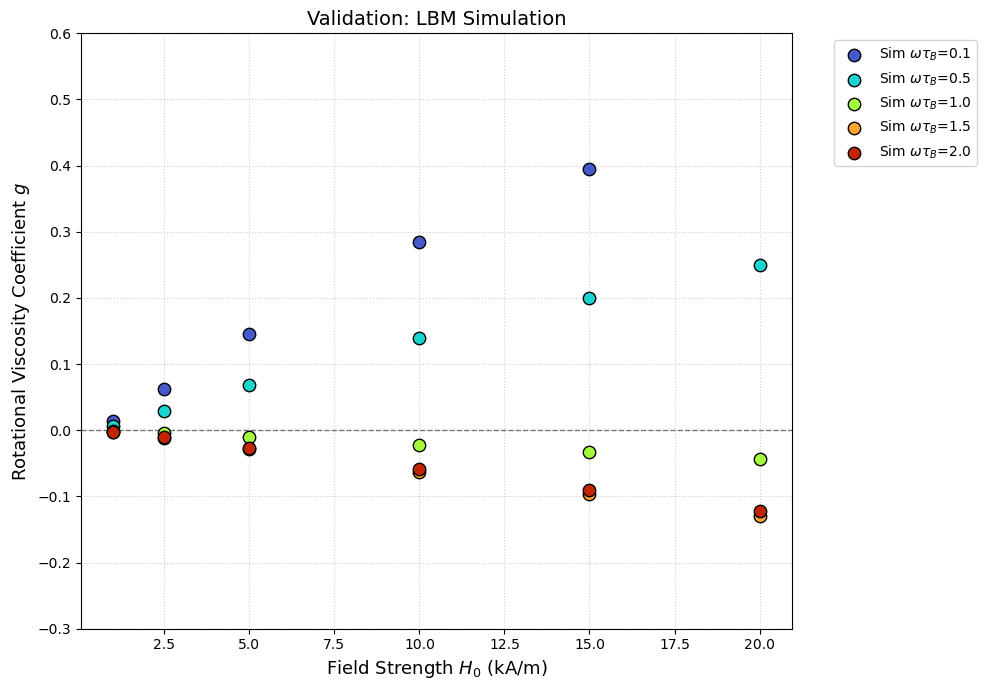

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
from scipy.special import iv

# --- 1. Constants (from phaseField_poiseuille.cpp) ---
nX, nY = 100, 25
phi_val = 1.0
F_px = 1e-4
tauB = 4.0
Href = 126.1585
Ms = 40.0 / Href
chi0 = 2.2

# Fluid properties
rho_l, rho_h = 1.0, 1.975
eta_l, eta_h = 0.0025, 0.05

# Effective base properties since phi = 1.0 everywhere initially
rho_base = rho_l + phi_val * (rho_h - rho_l) # 1.975
eta_base = eta_l + phi_val * (eta_h - eta_l) # 0.05

def poiseuille_theory(y, eta_eff):
    """
    Theoretical Poiseuille flow profile. 
    y bounds are -0.5 and nY-0.5 due to mid-grid bounce back.
    """
    return (F_px / (2.0 * eta_eff)) * (y + 0.5) * (nY - 0.5 - y)

def calculate_g_theory_2D(H0_real, wtB):
    """
    2D rotational viscosity coefficient g, consistent with the phase-field LBM simulation.
    H0_real is the physical field strength (in kA/m).
    """
    H0_real_arr = np.asarray(H0_real, dtype=float)
    H0_lbm = H0_real_arr / Href
    
    # xi = 2.0 * chi0 * H0_lbm / Ms
    xi = H0_real
    
    L_2D = np.where(xi < 1e-8, 0.5*xi, iv(1, xi) / iv(0, xi))
    
    # g_lbm = Delta_eta_lbm / (phi * eta_base)
    g_lbm = (tauB * Ms * L_2D * H0_lbm * (1.0 - wtB**2)) / (4.0 * eta_base * (1.0 + wtB**2)**2)
    
    # The classical Shliomis definition for g includes a 3/2 factor multiplier.
    g_physical = g_lbm * 1.5
    
    return np.nan_to_num(g_physical)

# --- 2. Simulation Data Processing ---
base_path = "output_poiseuille_updated"
results = []

if os.path.exists(base_path):
    for folder in os.listdir(base_path):
        if not folder.startswith("output_"):
            continue
            
        try:
            parts = folder.split('_')
            # Folder name format: output_{H0*Href}_{omega*tauB}
            h0_real = float(parts[1])
            wtB = float(parts[2])
            
            f_csv = os.path.join(base_path, folder, "output_t_100000.csv")
            if os.path.exists(f_csv):
                df = pd.read_csv(f_csv, skipinitialspace=True)
                
                # Average ux over x direction (i) to get y-profile
                u_profile = df.groupby('j')['ux'].mean().values
                
                # Fit the profile to find the effective viscosity
                popt, _ = curve_fit(poiseuille_theory, np.arange(nY), u_profile,
                                    p0=[eta_base], maxfev=5000, bounds=(1e-7, 2.0))
                
                # Calculate the simulated rotational viscosity coefficient 'g'
                g_sim_lbm = (popt[0] - eta_base) / (phi_val * eta_base)
                
                # Multiply by 1.5 to map to the classical Shliomis g definition
                g_sim_physical = g_sim_lbm * 1.5
                
                results.append({'H0_real': h0_real, 'wtB': wtB, 'g': g_sim_physical})
        except Exception as e:
            print(f"Skipping {folder}: {e}")
            continue

df = pd.DataFrame(results)

# --- 3. Plot ---
plt.figure(figsize=(10, 7))
H0_fine = np.linspace(0, 20, 300) # physical H0 values from 0 to 20 kA/m

if not df.empty:
    unique_wtBs = sorted(df['wtB'].unique())
    colors = plt.cm.turbo(np.linspace(0.1, 0.9, max(1, len(unique_wtBs))))

    for i, wtB in enumerate(unique_wtBs):
        c = colors[i]
        # g_th = calculate_g_theory_2D(H0_fine, wtB)
        # plt.plot(H0_fine, g_th, color=c, linewidth=2, alpha=0.8,
        #          label=r'Theory $\omega\tau_B$=' + f'{wtB:.1f}')
        
        sub = df[df['wtB'] == wtB]
        clean = sub[np.abs(sub['g']) < 1.5]
        plt.scatter(clean['H0_real'], clean['g'], color=c, s=80, edgecolors='k', zorder=5, label=r'Sim $\omega\tau_B$=' + f'{wtB:.1f}')

else:
    print("No complete simulation data found yet. Plotting theoretical curves.")
    for wtB, c in zip([0.1, 0.5, 1.0, 1.5, 2.0], ['royalblue', 'cyan', 'yellow', 'orange', 'red']):
        g_th = calculate_g_theory_2D(H0_fine, wtB)
        plt.plot(H0_fine, g_th, color=c, linewidth=2, alpha=0.8, label=r'Theory $\omega\tau_B=$' + f'{wtB:.1f}')

plt.axhline(0, color='black', linewidth=1, alpha=0.5, linestyle='--')
plt.xlabel(r'Field Strength $H_0$ (kA/m)', fontsize=13)
plt.ylabel(r'Rotational Viscosity Coefficient $g$', fontsize=13)
plt.title('Validation: LBM Simulation', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim(-0.3, 0.6)
plt.tight_layout()
# plt.savefig("validation_plot_updated.png")
# print("Saved plot to validation_plot_updated.png")



Grid from CSVs: nY = 25, walls trimmed 2 rows each side, 51 files averaged

Reference viscosity eta0 = 0.05   (measured from the xi0 = 0 run(s))
  nominal eta_base = 0.05
  FORCING FACTOR kappa = eta_base/eta0 = 1.0000    (must be 1.000)

RUNS
        xi0         wtB     eta_eff     eta_std           g       g_err         rms        umax  nfile
          1           0    0.053139  0.00016492      0.3139    0.016492  3.1131e-05   0.0058807     51
        2.5           0     0.05677   0.0005998     0.67698     0.05998  6.2184e-05    0.005505     51
          5           0    0.058212  0.00029955     0.82118    0.029955  7.3416e-05   0.0053681     51
         10           0     0.05913  0.00028772     0.91298    0.028772  8.0204e-05   0.0052848     51
         15           0    0.059393   0.0001842     0.93929     0.01842  8.2095e-05   0.0052613     51
         20           0    0.059545  0.00015251     0.95451    0.015251  8.3189e-05   0.0052478     51
          0         0.1        0.0

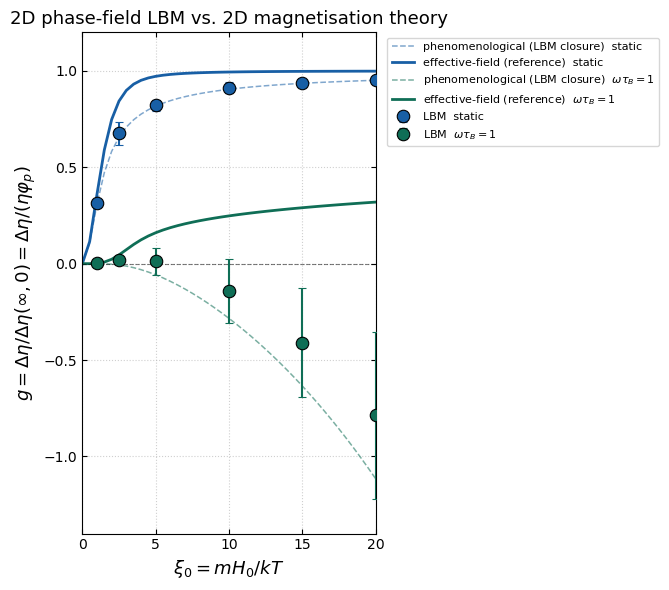

In [17]:
# =============================================================================
#  Validation of the 2D phase-field LBM against the 2D magnetisation theory
#
#  The LBM integrates the PHENOMENOLOGICAL (Shliomis) magnetisation equation
#      dM/dt = Omega ^ M - (M - M0)/tau_B + (1/4 eta phi_p)[M^2 H - M (M.H)]
#  so the curve it must land on is g_theory_phen.  The effective-field
#  (Martsenyuk-Raikher-Shliomis) result is plotted dashed for reference only.
#
#  2D conventions:  Delta_eta(inf,0) = eta*phi_p ;  g = Delta_eta/(eta*phi_p)
# =============================================================================

import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import ive

# -----------------------------------------------------------------------------
# 1. Must match the C++ parameter block
# -----------------------------------------------------------------------------
F_px   = 4e-6      # Fb_x
tau_B  = 20.0      # Brownian time, lattice steps
H0     = 0.1       # field amplitude, lattice units
phi_p  = 0.2       # particle volume fraction
mu0    = 1.0
eta_l, eta_h = 0.0025, 0.05
rho_l, rho_h = 1.0, 1.975

phi_val  = 1.0
eta_base = eta_l + phi_val*(eta_h - eta_l)
rho_base = rho_l + phi_val*(rho_h - rho_l)
c_s      = 1.0/np.sqrt(3.0)

BASE_PATH = "output_poiseuille_latest"
AVG_FRAC  = 0.50    # fraction of output files (from the end) averaged
TRIM_FRAC = 0.10    # fraction of nY dropped at EACH wall before fitting
MIN_TRIM  = 2

# -----------------------------------------------------------------------------
# 2. 2D Langevin function and helpers
# -----------------------------------------------------------------------------
TINY = 1e-3

def L2(x):
    x = np.asarray(x, float)
    ax = np.abs(x); axs = np.where(ax < TINY, 1.0, ax)
    r = ive(1, axs)/ive(0, axs)
    return np.where(ax < TINY, x/2.0 - x**3/16.0, np.sign(x)*r)

def _aux2D(x):
    """(L2, L2/L2', L2/(x L2'), B) from one Bessel evaluation."""
    x = np.asarray(x, float)
    ax = np.abs(x); small = ax < TINY
    axs = np.where(small, 1.0, ax)
    r = ive(1, axs)/ive(0, axs)
    Lv  = np.where(small, x/2.0 - x**3/16.0, np.sign(x)*r)
    dLv = np.where(small, 0.5 - 3.0*x**2/16.0, 1.0 - r*r - r/axs)
    xs  = np.where(small, 1.0, x)
    Ls  = np.where(small, 1.0, Lv)
    LdL = np.where(small, x + x**3/4.0,       Lv/dLv)
    Dv  = np.where(small, 1.0 + ax**2/4.0,    Lv/(xs*dLv))
    Bv  = np.where(small, -x/4.0 + x**3/96.0, 2.0/xs - 1.0/Ls)   # 2/x - 1/L
    return Lv, LdL, Dv, Bv

# ---- PHENOMENOLOGICAL closure: what the LBM solves --------------------------
def g_static_phen(xi0):
    """Static field:  g = xi L2 /(1 + xi L2)."""
    x = np.abs(np.asarray(xi0, float))
    z = x*L2(x)
    return z/(1.0 + z)

def g_theory_phen(xi0, omega_tauB, h_target=0.01, n_avg=6, settle_time=60.0):
    """
    Time in units of tau_B, so omega_tauB is the dimensionless frequency.
        dF/dt = L2(xi0 cos wt) - F
        dG/dt = F - (1 + xi0 cos(wt) F) G
        g     = xi0 <G cos wt>
    """
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if omega_tauB <= 1e-12:
        return g_static_phen(xi0)
    om = float(omega_tauB)
    T  = 2.0*np.pi/om
    N  = max(1200, int(np.ceil(T/h_target)))
    h  = T/N
    n_settle = max(4, int(np.ceil(settle_time/T)))

    def der(t, F, G):
        c = np.cos(om*t)
        return (L2(xi0*c) - F,
                F - (1.0 + xi0*c*F)*G,
                G*c)

    def rk4(t, F, G, I):
        a1,b1,c1 = der(t,     F,        G)
        a2,b2,c2 = der(t+h/2, F+h/2*a1, G+h/2*b1)
        a3,b3,c3 = der(t+h/2, F+h/2*a2, G+h/2*b2)
        a4,b4,c4 = der(t+h,   F+h*a3,   G+h*b3)
        return (F+h/6*(a1+2*a2+2*a3+a4),
                G+h/6*(b1+2*b2+2*b3+b4),
                I+h/6*(c1+2*c2+2*c3+c4))

    F = np.zeros_like(xi0); G = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0
    for _ in range(n_settle*N):
        F, G, _ = rk4(t, F, G, np.zeros_like(I)); t += h
    for _ in range(n_avg*N):
        F, G, I = rk4(t, F, G, I); t += h
    return xi0*I/(n_avg*T)

# ---- EFFECTIVE-FIELD closure: reference only --------------------------------
def g_static_ef(xi0):
    x = np.abs(np.asarray(xi0, float))
    Lv = L2(x)
    return np.where(x < 1e-8, x*x/2.0, x*Lv**2/(x - Lv + 1e-300))

def g_theory_ef(xi0, omega_tauB, h_target=0.02, n_avg=4, settle_time=40.0):
    if omega_tauB <= 1e-12:
        return g_static_ef(xi0)
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    om  = float(omega_tauB)
    T   = 2.0*np.pi/om
    N   = max(800, int(np.ceil(T/h_target)))
    h   = T/N
    n_settle = max(3, int(np.ceil(settle_time/T)))

    def der(t, xe, Y):
        c = np.cos(om*t)
        Lv, LdL, Dv, Bv = _aux2D(xe)
        return (-LdL + Dv*xi0*c, Lv - Y*(1.0 - xi0*c*Bv), Y*c)

    def rk4(t, xe, Y, I):
        a1,b1,c1 = der(t,     xe,        Y)
        a2,b2,c2 = der(t+h/2, xe+h/2*a1, Y+h/2*b1)
        a3,b3,c3 = der(t+h/2, xe+h/2*a2, Y+h/2*b2)
        a4,b4,c4 = der(t+h,   xe+h*a3,   Y+h*b3)
        return (xe+h/6*(a1+2*a2+2*a3+a4),
                Y +h/6*(b1+2*b2+2*b3+b4),
                I +h/6*(c1+2*c2+2*c3+c4))

    xe = xi0.copy(); Y = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0
    for _ in range(n_settle*N):
        xe, Y, _ = rk4(t, xe, Y, np.zeros_like(I)); t += h
    for _ in range(n_avg*N):
        xe, Y, I = rk4(t, xe, Y, I); t += h
    return xi0*I/(n_avg*T)

# ---- exact nonlinear-in-Omega static solution (diagnostic) ------------------
def g_static_nonlinear(xi0, a, Ms_code, H, k):
    """
    Exact steady state of the code's own magnetisation equation, keeping ALL
    orders in a = tau_B*Omega:
        My = a Mx /(1 + s Mx),   Mx = M0 - a My + s My^2,   s = tau_B k H
    Returns g = My H k / Omega.  Reduces to xi L2/(1+xi L2) as a -> 0.
    """
    M0 = Ms_code*float(L2(np.array([xi0]))[0])
    s  = tau_B*k*H
    Mx = M0
    for _ in range(200):
        My = a*Mx/(1.0 + s*Mx)
        Mx_new = M0 - a*My + s*My*My
        Mx = 0.5*(Mx + Mx_new)          # damped iteration
    My = a*Mx/(1.0 + s*Mx)
    Omega = a/tau_B
    return My*H*k/Omega if Omega > 0 else 0.0

# -----------------------------------------------------------------------------
# 3. eta_eff from one run (grid inferred from the data)
# -----------------------------------------------------------------------------
def fit_eta(prof, nY):
    trim = max(MIN_TRIM, int(round(TRIM_FRAC*nY)))
    if nY - 2*trim < 4:
        trim = max(1, (nY - 4)//2)
    j = np.arange(nY)
    m = (j >= trim) & (j < nY - trim)

    def model(y, eta_eff):
        return (F_px/(2.0*eta_eff))*(y + 0.5)*(nY - 0.5 - y)

    popt, _ = curve_fit(model, j[m], prof[m], p0=[eta_base],
                        bounds=(1e-12, 1e4), maxfev=40000)
    resid = prof[m] - model(j[m], popt[0])
    denom = max(np.max(np.abs(prof)), 1e-30)
    return float(popt[0]), float(np.sqrt(np.mean(resid**2))/denom), trim

def eta_from_folder(folder):
    files = sorted(glob.glob(os.path.join(folder, "output_t_*.csv")),
                   key=lambda s: int(re.search(r"output_t_(\d+)\.csv", s).group(1)))
    if not files:
        return None
    keep = files[int(len(files)*(1.0 - AVG_FRAC)):] or files[-1:]

    etas, rmss, umaxs, nY_seen, trim = [], [], [], None, None
    for f in keep:
        d = pd.read_csv(f, skipinitialspace=True)
        if 'ux' not in d.columns or 'j' not in d.columns:
            continue
        prof = d.groupby('j')['ux'].mean().sort_index().values
        nY = len(prof)
        if nY_seen is None: nY_seen = nY
        elif nY != nY_seen: continue
        if not np.all(np.isfinite(prof)): continue
        try:
            e, r, trim = fit_eta(prof, nY)
        except Exception:
            continue
        etas.append(e); rmss.append(r); umaxs.append(np.max(np.abs(prof)))

    if not etas:
        return None
    etas = np.asarray(etas)
    return dict(eta_eff=etas.mean(), eta_std=etas.std(),
                rms=float(np.mean(rmss)), umax=float(np.mean(umaxs)),
                nfile=len(etas), nY=nY_seen, trim=trim)

# -----------------------------------------------------------------------------
# 4. Walk the output tree
# -----------------------------------------------------------------------------
pat = re.compile(r"^output_xi0_([-\d.eE+]+)_wtB_([-\d.eE+]+)$")

runs = []
if not os.path.isdir(BASE_PATH):
    raise SystemExit(f"'{BASE_PATH}' not found.")
for name in sorted(os.listdir(BASE_PATH)):
    folder = os.path.join(BASE_PATH, name)
    if not os.path.isdir(folder):
        continue
    m = pat.match(name)
    if m is None:
        continue
    out = eta_from_folder(folder)
    if out is None:
        print(f"  skipped (no usable CSVs): {name}")
        continue
    out.update(xi0=float(m.group(1)), wtB=float(m.group(2)))
    runs.append(out)

df = pd.DataFrame(runs)
if df.empty:
    raise SystemExit("No usable runs found.")

nY_data = int(df['nY'].mode().iloc[0])
h_half  = nY_data/2.0
print(f"\nGrid from CSVs: nY = {nY_data}, walls trimmed "
      f"{int(df['trim'].mode().iloc[0])} rows each side, "
      f"{int(df['nfile'].mode().iloc[0])} files averaged")

# -----------------------------------------------------------------------------
# 5. Reference viscosity, forcing-factor check, g
# -----------------------------------------------------------------------------
zero = df[df['xi0'] < 1e-9]
if len(zero):
    eta0  = float(zero['eta_eff'].mean())
    umax0 = float(zero['umax'].mean())
    src   = "measured from the xi0 = 0 run(s)"
else:
    eta0, umax0 = eta_base, float(df['umax'].max())
    src = "NOMINAL eta_h -- no xi0 = 0 run present"

kappa = eta_base/eta0        # forcing multiplier actually realised by the code
print(f"\nReference viscosity eta0 = {eta0:.6g}   ({src})")
print(f"  nominal eta_base = {eta_base:.6g}")
print(f"  FORCING FACTOR kappa = eta_base/eta0 = {kappa:.4f}    (must be 1.000)")
if abs(kappa - 1.0) > 0.02:
    print(f"  >> forces in the LBM are {kappa:.2f}x the intended value.")
    print(f"     g is inflated by exactly this factor, and the true velocity")
    print(f"     and vorticity are {kappa:.2f}x larger than the nominal ones.")

# g in 2D:  Delta_eta = eta * phi_p * g
df['g']     = (df['eta_eff'] - eta0)/(eta0*phi_p)
df['g_err'] = df['eta_std']/(eta0*phi_p)

print("\nRUNS")
cols = ['xi0','wtB','eta_eff','eta_std','g','g_err','rms','umax','nfile']
print(df.sort_values(['wtB','xi0'])[cols].to_string(
    index=False, float_format=lambda v: f"{v:11.5g}"))

# -----------------------------------------------------------------------------
# 6. Regime diagnostics -- computed FROM THE DATA, not from assumptions
# -----------------------------------------------------------------------------
print("\nREGIME DIAGNOSTICS  (measured, not assumed)")
print("-"*74)
umax_all = float(df['umax'].max())
Ma       = umax_all/c_s
Om_max   = 2.0*umax_all/h_half          # parabola: |u'|_wall = 2 umax/h, Om=|u'|/2
print(f"  u_max (all runs)   = {umax_all:.4e}      Mach = {Ma:.4f}"
      "   (need << 1; < 0.05 is safe)")
print(f"  Omega_max          = {Om_max:.4e}")
print(f"  tau_B * Omega_max  = {tau_B*Om_max:.4f}"
      "   (LINEAR RESPONSE needs << 1; < 0.02 is safe)")
if tau_B*Om_max > 0.05:
    print("  >> the theory is linearised in Omega*tau_B; above ~0.05 the")
    print("     simulation solves a DIFFERENT problem and cannot agree.")

tau_h = rho_base*h_half**2/eta_base
for wtB in sorted(df['wtB'].unique()):
    if wtB <= 1e-12:
        print(f"  wtB = 0    : static field, no time-scale requirement")
        continue
    period = 2.0*np.pi*tau_B/wtB
    print(f"  wtB = {wtB:<4g}: field period = {period:8.1f} steps, "
          f"tau_h = {tau_h:8.1f}, ratio = {period/tau_h:.4f} (need << 1); "
          f"{period:.0f} steps/period (need >> 1)")

xi_max = df['xi0'].max()
print(f"  Ms required for xi0 = {xi_max:g}: "
      f"{4.0*eta_h*phi_p*xi_max/(mu0*tau_B*H0):.5g}")
print("-"*74)

# nonlinear-in-Omega estimate of the static deficit
stat = df[(df['wtB'] < 1e-12) & (df['xi0'] > 1e-9)].sort_values('xi0')
if len(stat) and tau_B*Om_max > 0.05:
    k_bk = 1.0/(4.0*eta_h*phi_p)
    print("\n  Static runs: linear theory vs exact nonlinear-in-Omega solution")
    print("   xi0    g_linear   g_nl(mid)   g_nl(wall)   g_measured")
    for _, r in stat.iterrows():
        x   = r['xi0']
        Msc = 4.0*eta_h*phi_p*x/(mu0*tau_B*H0)
        gl  = float(g_static_phen(np.array([x]))[0])
        gm  = g_static_nonlinear(x, 0.5*tau_B*Om_max, Msc, H0, k_bk)
        gw  = g_static_nonlinear(x, 1.0*tau_B*Om_max, Msc, H0, k_bk)
        print(f"  {x:5.1f}   {gl:8.4f}   {gm:8.4f}   {gw:9.4f}   {r['g']:9.4f}")
    print("  (if g_measured tracks the nonlinear columns rather than g_linear,")
    print("   the disagreement is the Omega*tau_B violation, not a code bug)")

df = df[df['xi0'] > 1e-9]

# -----------------------------------------------------------------------------
# 7. Plot
# -----------------------------------------------------------------------------
wtB_list = sorted(df['wtB'].unique())
xi_fine  = np.linspace(0.0, 20.0, 41)
colors   = ['#185FA5', '#0F6E56', '#BA7517', '#D85A30', '#534AB7', '#8C1D40']

plt.figure(figsize=(9.5, 6))
for wtB, c in zip(wtB_list, colors*4):
    lab = 'static' if wtB <= 1e-12 else rf'$\omega\tau_B={wtB:g}$'
    print(f"theory curves, omega*tau_B = {wtB} ...", flush=True)
    # plt.plot(xi_fine, g_theory_phen(xi_fine, wtB), color=c, lw=2.0,
    #          label=f'phenomenological (LBM closure)  {lab}')
    # plt.plot(xi_fine, g_theory_ef(xi_fine, wtB), color=c, lw=1.1, ls='--',
    #          alpha=0.55, label=f'effective-field (reference)  {lab}')
    plt.plot(xi_fine, g_theory_phen(xi_fine, wtB), color=c, lw=1.1, ls='--',
                 alpha=0.55, label=f'phenomenological (LBM closure)  {lab}')
    plt.plot(xi_fine, g_theory_ef(xi_fine, wtB), color=c, lw = 2.0,
                 label=f'effective-field (reference)  {lab}')
    s = df[np.isclose(df['wtB'], wtB)].sort_values('xi0')
    if len(s):
        plt.errorbar(s['xi0'], s['g'], yerr=s['g_err'], fmt='o', color=c,
                     ms=9, mec='k', mew=0.8, capsize=3, ls='none', zorder=5,
                     label=f'LBM  {lab}')

plt.axhline(0, color='k', lw=0.8, ls='--', alpha=0.5)
plt.xlabel(r'$\xi_0 = m H_0 / kT$', fontsize=13)
plt.ylabel(r'$g=\Delta\eta/\Delta\eta(\infty,0)=\Delta\eta/(\eta\varphi_p)$',
           fontsize=13)
plt.title('2D phase-field LBM vs. 2D magnetisation theory', fontsize=13)
plt.xlim(0, 20); plt.ylim(-1.4, 1.2)
plt.grid(True, ls=':', alpha=0.6)
plt.tick_params(direction='in', top=True, right=True)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout(rect=[0, 0, 0.72, 1])
plt.savefig("validation_2D.png", dpi=150)
plt.show()